# 🥣 Muesli Distribution Company — EDA Project

## Business Context

A Muesli distribution company wants to understand and improve their delivery process.  
They have asked us to develop **KPIs** that track the health of their business at each stage.

### The order process (as described by the company):

```
Day 1: Order Received
    ↓  (warehouse processes order — normally 2 days)
Day ~3: Order Ready to Ship
    ↓  (ships on next truck — Mon/Wed/Fri only | Express: same day)
Day ~4: On Truck (leaves warehouse)
    ↓  (logistics company delivers — avg 3 days)
Day ~7: Delivered to Customer
```

### Key assumptions to validate:
- Warehouse processes orders in **~2 days**
- Trucks leave **Mon, Wed, Fri** only
- **Express** orders leave on truck the same day they are ready
- Logistics delivers in **average 3 days**
- Weekend orders are processed on **Monday**

In [1]:
#I had to google this one cause I had no idea how to import a zip file :3

import zipfile

# Unzip the data file
with zipfile.ZipFile('data.zip', 'r') as zip_ref:
    zip_ref.extractall('data')  # extracts into a folder called 'data'

## 1. Load the Data

The Excel file has **4 sheets**:
- **Orders** — all orders with customer and product details (~10k rows)
- **Order Process Data** — order date + truck scan date for ~5900 orders
- **InternData Study** — ready to ship + pickup dates recorded by interns (only 290 rows!)
- **Campaign Data** — arrival scan dates from QR code marketing campaign (333 rows)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Load all 4 sheets
# Note: Orders sheet has a header row issue, so we use header=1

orders      = pd.read_excel('data/Muesli Project raw data.xlsx', sheet_name='Orders', header=1)
process     = pd.read_excel('data/Muesli Project raw data.xlsx', sheet_name='Order Process Data')
intern_data = pd.read_excel('data/Muesli Project raw data.xlsx', sheet_name='InternData Study')
campaign    = pd.read_excel('data/Muesli Project raw data.xlsx', sheet_name='Campaign Data')

#Checking dimensions to see if everything got loaded properly.

print('Orders shape:     ', orders.shape)
print('Process shape:    ', process.shape)
print('Intern data shape:', intern_data.shape)
print('Campaign shape:   ', campaign.shape)

Orders shape:      (9994, 19)
Process shape:     (5899, 5)
Intern data shape: (290, 3)
Campaign shape:    (333, 3)


## 2. Exploratory Data Analysis (EDA)
### 2.1 Quick look at each dataset

In [3]:
# Main orders dataset
print('=== ORDERS ===')
display(orders.head(3))
print('\nColumns:', orders.columns.tolist())
print('\nDate range:', orders['Order Date'].min(), 'to', orders['Order Date'].max())

=== ORDERS ===


,Index,Order ID,Order Date,Ship Mode,Customer ID,Customer Name,Origin Channel,Country/Region,City,State,Postal Code,Region,Category,Sub-Category,Product ID,Sales,Quantity,Discount,Profit
0,27,CA-2019-121755,2019-01-16,Second Class,EH-13945,Eric Hoffmann,Email,United States,Los Angeles,California,90049.0,West,Special Projects Muesil,Gluten Free,TEC-AC-10003027,90.57,3,0.0,11.7741
1,45,CA-2019-118255,2019-03-11,First Class,ON-18715,Odella Nelson,Sales,United States,Eagan,Minnesota,55122.0,Central,Special Projects Muesil,Gluten Free,TEC-AC-10000171,45.98,2,0.0,19.7714
2,48,CA-2019-169194,2019-06-20,Standard Class,LH-16900,Lena Hernandez,Email,United States,Dover,Delaware,19901.0,East,Special Projects Muesil,Gluten Free,TEC-AC-10002167,45.00,3,0.0,4.9500



Columns: ['Index', 'Order ID', 'Order Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Origin Channel', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Product ID', 'Sales', 'Quantity', 'Discount', 'Profit']

Date range: 2017-01-03 00:00:00 to 2020-12-30 00:00:00


In [ ]:
# Order process data — our main KPI source
print('=== ORDER PROCESS DATA ===')
display(process.head(3))
#having a look and the unique values of the ship mode just to have a look if there are any surprises, typos and so on
print('\nShip Modes:', process['Ship Mode'].unique())
print('Date range:', process['Order Date'].min(), 'to', process['Order Date'].max())

=== ORDER PROCESS DATA ===


,Row ID,Order ID,Order Date,On Truck Scan Date,Ship Mode
0,3074,CA-2019-125206,2019-01-03,2019-01-07,Express
1,4919,CA-2019-160304,2019-01-02,2019-01-09,Standard Processing
2,4920,CA-2019-160304,2019-01-02,2019-01-09,Standard Processing



Ship Modes: <StringArray>
['Express', 'Standard Processing']
Length: 2, dtype: str
Date range: 2019-01-02 00:00:00 to 2020-12-30 00:00:00


In [ ]:
# Intern data — partial data on warehouse stage
print('=== INTERN DATA ===')
display(intern_data.head(3))
print(f'\nOnly {len(intern_data)} rows — interns could not record everything!') 

=== INTERN DATA ===


,Order ID,Ready to Ship Date,Pickup Date
0,CA-2019-116540,2019-09-02,2019-09-03
1,CA-2019-116540,2019-09-02,2019-09-03
2,CA-2019-129847,2019-09-04,2019-09-04



Only 290 rows — interns could not record everything!


In [6]:
# Campaign data — partial data on delivery stage
print('=== CAMPAIGN DATA (Arrival Scans) ===')
display(campaign.head(3))
print(f'\nOnly {len(campaign)} rows — not all customers scanned the QR code!')

=== CAMPAIGN DATA (Arrival Scans) ===


,Order ID,Arrival Scan Date,Customer Name
0,CA-2019-109666,2019-05-03,Kunst Miller
1,CA-2019-138933,2019-05-03,Jack Lebron
2,CA-2019-130001,2019-05-03,Heather Kirkland



Only 333 rows — not all customers scanned the QR code!


### Little recap of the data frames, to help me understand what can I do with them.

1. orders (~10k rows)
The master dataset with everything about each order — customer info, product, city, region, sales, profit, discount etc. It covers 2017–2020. However for this project I find it the least useful of the four because it doesn't have the dates we need to track the delivery process. It's more useful if you want to analyse things like which products sell most or which regions generate most profit.
2. process (~5900 rows)
I feel this is the backbone of the project. It has the two dates the company is most confident about — Order Date and On Truck Scan Date — plus the Ship Mode (Express vs Standard). This is the dataset where we can calculate the total time an order spends in the warehouse for almost 6000 orders. I can see a lot of KPIs coming from here.
3. intern_data (only 290 rows)
This is the missing piece of the warehouse puzzle. It tells us when an order was Ready to Ship and when it was actually Picked Up by the truck. Without this we can't split the warehouse time into "processing time" and "waiting for truck" separately. The problem is it's tiny — only 290 rows — because interns could only record so many orders. So conclusions from this one should be taken with a pinch of salt!
4. campaign (only 333 rows)
This is the only window into what happens after the truck leaves. It tells us the Arrival Scan Date — when the customer actually received the order — collected via a QR code marketing campaign. Again very partial data, but it's the only way we can measure the logistics company's performance. Also potentially biased — only customers motivated enough to scan a QR code for a prize are included.

### 2.2 Missing values check.

In [ ]:
#I wanna check null values but for the orders df I only wanna print the column that actually has one (cause there are 19).

print('Missing values per dataset:')
print('\n--- Orders ---')
print(orders.isnull().sum()[orders.isnull().sum() > 0])
#and it seems postal code has 11 nulls
print('\n--- Process Data ---')
print(process.isnull().sum())
print('\n--- Intern Data ---')
print(intern_data.isnull().sum())
print('\n--- Campaign Data ---')
print(campaign.isnull().sum())

Missing values per dataset:

--- Orders ---
Postal Code    11
dtype: int64

--- Process Data ---
Row ID                0
Order ID              0
Order Date            0
On Truck Scan Date    0
Ship Mode             0
dtype: int64

--- Intern Data ---
Order ID              0
Ready to Ship Date    0
Pickup Date           0
dtype: int64

--- Campaign Data ---
Order ID             0
Arrival Scan Date    0
Customer Name        0
dtype: int64


### 2.3 Order Value Overview

In [ ]:
# Orders by ship mode
print('Orders by Ship Mode (Process Data):')
print(process['Ship Mode'].value_counts())
print(f'\nExpress share: {process["Ship Mode"].value_counts(normalize=True)["Express"]:.2%}')
#In the last line I just normalize the counts to get us some nice proportions and then play with the python f string syntax to returns us 
# a nice percentage number with two decimals

Orders by Ship Mode (Process Data):
Ship Mode
Standard Processing    4596
Express                1303
Name: count, dtype: int64

Express share: 22.09%


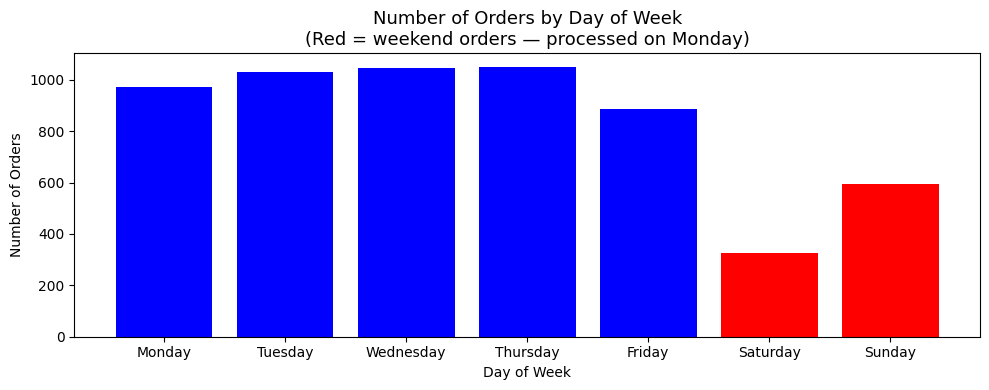

Weekend orders: 918 (15.6% of total)


In [11]:
# Orders by day of week — I thought it might be important to understand weekend order behaviour
process['order_day'] = process['Order Date'].dt.day_name() #adding a new column with the name of the days

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = process['order_day'].value_counts().reindex(day_order) #here I am counting how many orders per day do I have but 
#I need to re index them to the order of the days because naturally they will come sorted by the count

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['red' if d in ['Saturday', 'Sunday'] else 'blue' for d in day_order]
ax.bar(day_counts.index, day_counts.values, color=colors)
ax.set_title('Number of Orders by Day of Week\n(Red = weekend orders — processed on Monday)', fontsize=13)
ax.set_ylabel('Number of Orders')
ax.set_xlabel('Day of Week')
plt.tight_layout()
plt.show()

weekend_orders = process[process['order_day'].isin(['Saturday', 'Sunday'])]
print(f'Weekend orders: {len(weekend_orders)} ({len(weekend_orders)/len(process):.1%} of total)')

## 3. KPI Development — Time at Each Stage

We will calculate the time taken at each stage of the order process and compare it to what the company told us.

| Stage | From | To | Data Available? |
|---|---|---|---|
| Warehouse Processing | Order Date | Ready to Ship Date | ⚠️ Partial (intern data) |
| Waiting for Truck | Ready to Ship Date | On Truck Scan Date | ⚠️ Partial (intern data) |
| Full Warehouse Time | Order Date | On Truck Scan Date | ✅ Complete |
| Delivery | On Truck Scan Date | Arrival Scan Date | ⚠️ Partial (campaign data) |

### 3.1 Stage 1 — Full Warehouse Time (Order Date → On Truck)
This is our most **complete** dataset. The company has both dates for all orders.

In [ ]:
# 12(order date to truck scan)
process['total_warehouse_days'] = (process['On Truck Scan Date'] - process['Order Date']).dt.days

print('Total Warehouse Time (Order → On Truck):')
print(process['total_warehouse_days'].describe().round(2))

Total Warehouse Time (Order → On Truck):
count    5899.00
mean        6.12
std         2.51
min         0.00
25%         5.00
50%         7.00
75%         8.00
max        12.00
Name: total_warehouse_days, dtype: float64


- Wow XD company implying the total warehouse time should be around 3-4 days. But the actual average is 6.12 days — that's almost double what they claimed!

- And that's just the average — the max is 12 days, meaning some orders spent nearly two weeks just sitting in the warehouse before even leaving on a truck!

- A key finding of the whole project — the warehouse is the biggest bottleneck in the delivery process. 

Warehouse Time by Ship Mode:
                      count  mean   std  min  25%  50%  75%   max
Ship Mode                                                        
Express              1303.0  2.57  1.64  0.0  1.0  3.0  4.0   6.0
Standard Processing  4596.0  7.13  1.65  2.0  6.0  7.0  8.0  12.0


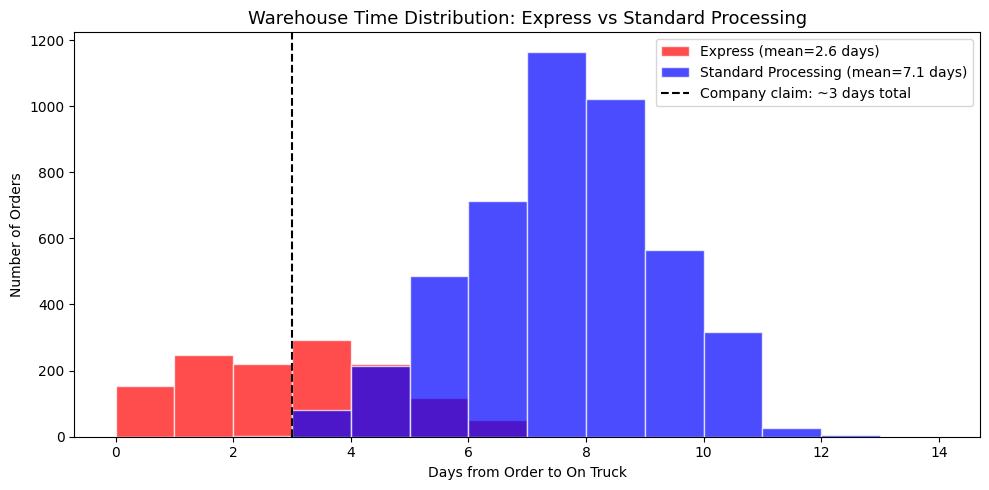

In [14]:
# Compare Express vs Standard Processing
print('Warehouse Time by Ship Mode:')
print(process.groupby('Ship Mode')['total_warehouse_days'].describe().round(2))

fig, ax = plt.subplots(figsize=(10, 5))

#using a for loop to plot two hist at once
for mode, color in [('Express', 'red'), ('Standard Processing', 'blue')]:
    #in the subset first we are selecting the specific rows for a specific column
    subset = process[process['Ship Mode'] == mode]['total_warehouse_days']
    ax.hist(subset, bins=range(0, 15), alpha=0.7, color=color, label=f'{mode} (mean={subset.mean():.1f} days)', edgecolor='white')

ax.axvline(x=3, color='black', linestyle='--', linewidth=1.5, label='Company claim: ~3 days total')
ax.set_title('Warehouse Time Distribution: Express vs Standard Processing', fontsize=13)
ax.set_xlabel('Days from Order to On Truck')
ax.set_ylabel('Number of Orders')
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Stage 2 — Warehouse Processing Time (Order Date → Ready to Ship)
Partial data only — recorded by interns. The company claims this takes **~2 days**.

In [15]:
# Merge process data with intern data to get Ready to Ship dates
process_intern = process.merge(intern_data, on='Order ID', how='left')

# Calculate processing time: Order Date → Ready to Ship
process_intern['processing_time'] = (process_intern['Ready to Ship Date'] - process_intern['Order Date']).dt.days

# Only look at rows where intern data is available
has_intern = process_intern.dropna(subset=['processing_time'])

print(f'Orders with intern data: {len(has_intern)} out of {len(process)} ({len(has_intern)/len(process):.1%})')
print(f'\nProcessing Time (Order → Ready to Ship):')
print(has_intern['processing_time'].describe().round(2))
print(f'\n⚠️  Company claims ~2 days. Actual average: {has_intern["processing_time"].mean():.1f} days')

Orders with intern data: 753 out of 5899 (12.8%)

Processing Time (Order → Ready to Ship):
count    753.00
mean       4.32
std        1.79
min        0.00
25%        3.00
50%        5.00
75%        6.00
max        8.00
Name: processing_time, dtype: float64

⚠️  Company claims ~2 days. Actual average: 4.3 days


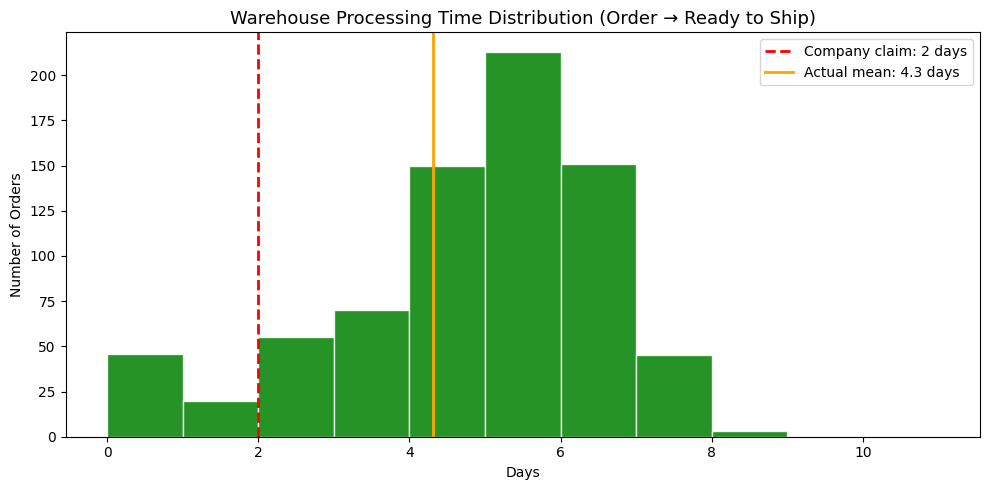

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(has_intern['processing_time'], bins=range(0, 12), color='green', edgecolor='white', alpha=0.85)
ax.axvline(x=2, color='red', linestyle='--', linewidth=2, label='Company claim: 2 days')
ax.axvline(x=has_intern['processing_time'].mean(), color='orange', linestyle='-', linewidth=2,
           label=f'Actual mean: {has_intern["processing_time"].mean():.1f} days')
ax.set_title('Warehouse Processing Time Distribution (Order → Ready to Ship)', fontsize=13)
ax.set_xlabel('Days')
ax.set_ylabel('Number of Orders')
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Stage 3 — Waiting for Truck (Ready to Ship → On Truck)
Trucks leave Mon, Wed, Fri. Express orders ship the same day they are ready.

In [20]:
# Calculate wait time for truck: Ready to Ship → On Truck (Pickup Date from intern data)
has_intern['wait_for_truck'] = (has_intern['Pickup Date'] - has_intern['Ready to Ship Date']).dt.days

print('Wait for Truck Time (Ready to Ship → Pickup):')
print(has_intern['wait_for_truck'].describe().round(2))
print()
print('Distribution:')
print(has_intern['wait_for_truck'].value_counts().sort_index())

# Same day pickup (Express behaviour)
same_day = (has_intern['wait_for_truck'] == 0).sum()
print(f'\nSame-day pickup (0 days wait): {same_day} orders ({same_day/len(has_intern):.1%})')

Wait for Truck Time (Ready to Ship → Pickup):
count    753.00
mean       1.75
std        0.95
min        0.00
25%        1.00
50%        2.00
75%        2.00
max        3.00
Name: wait_for_truck, dtype: float64

Distribution:
wait_for_truck
0     94
1    174
2    308
3    177
Name: count, dtype: int64

Same-day pickup (0 days wait): 94 orders (12.5%)


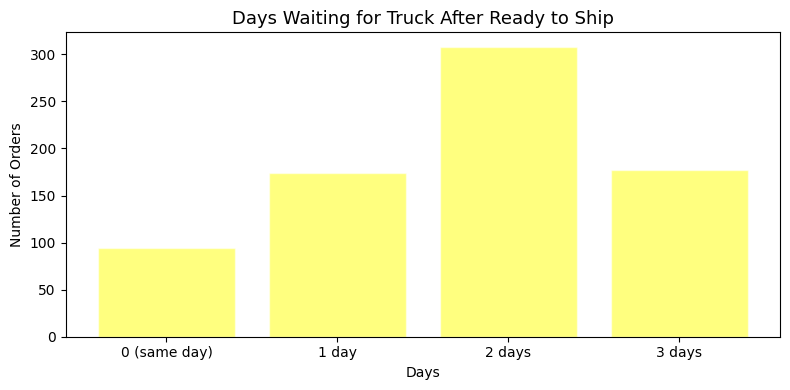

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
wait_counts = has_intern['wait_for_truck'].value_counts().sort_index()
ax.bar(wait_counts.index, wait_counts.values, color='yellow', edgecolor='white', alpha=0.5)
ax.set_title('Days Waiting for Truck After Ready to Ship', fontsize=13)
ax.set_xlabel('Days')
ax.set_ylabel('Number of Orders')
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(['0 (same day)', '1 day', '2 days', '3 days'])
plt.tight_layout()
plt.show()

### 3.4 Stage 4 — Delivery Time (On Truck → Arrival)
Logistics company claims average delivery is **3 days**. We check using the campaign (QR code) data.

In [24]:
# Merge with campaign data to get arrival dates
process_delivery = process.merge(campaign, on='Order ID', how='left')
process_delivery['delivery_days'] = (process_delivery['Arrival Scan Date'] - process_delivery['On Truck Scan Date']).dt.days

has_delivery = process_delivery.dropna(subset=['delivery_days'])

print(f'Orders with delivery data: {len(has_delivery)} out of {len(process)} ({len(has_delivery)/len(process):.1%})')
print(f'\nDelivery Time (On Truck → Arrival):')
print(has_delivery['delivery_days'].describe().round(2))
print(f'\n⚠️  Logistics claims 3 days average. Actual average: {has_delivery["delivery_days"].mean():.1f} days')

Orders with delivery data: 668 out of 5899 (11.3%)

Delivery Time (On Truck → Arrival):
count    668.00
mean       4.56
std        1.21
min        1.00
25%        4.00
50%        5.00
75%        5.00
max        7.00
Name: delivery_days, dtype: float64

⚠️  Logistics claims 3 days average. Actual average: 4.6 days


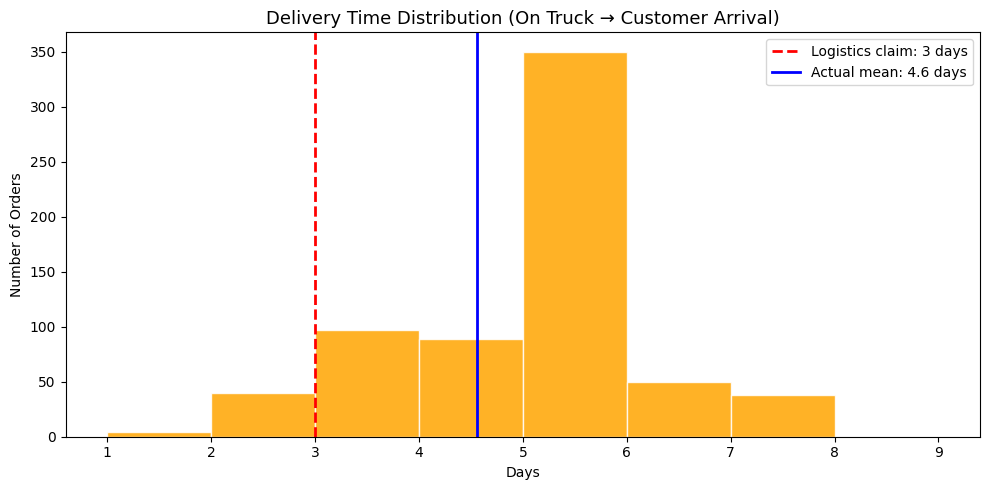

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(has_delivery['delivery_days'], bins=range(1, 10), color='orange', edgecolor='white', alpha=0.85)
ax.axvline(x=3, color='red', linestyle='--', linewidth=2, label='Logistics claim: 3 days')
ax.axvline(x=has_delivery['delivery_days'].mean(), color='blue', linestyle='-', linewidth=2,
           label=f'Actual mean: {has_delivery["delivery_days"].mean():.1f} days')
ax.set_title('Delivery Time Distribution (On Truck → Customer Arrival)', fontsize=13)
ax.set_xlabel('Days')
ax.set_ylabel('Number of Orders')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Match / Mismatch Summary

How do company claims compare to what the data shows?

In [31]:
# Summary table of claims vs reality
summary = pd.DataFrame({
    'Stage': [
        'Warehouse Processing (Order → Ready)',
        'Wait for Truck (Ready → On Truck)',
        'Delivery (On Truck → Customer)',
        'Total Warehouse (Order → On Truck) — Standard',
        'Total Warehouse (Order → On Truck) — Express'
    ],
    'Company Claim': ['~2 days', '1 day (next truck)', '~3 days', '~3 days', 'Same day pickup'],
    'Actual Average': [
        f"{has_intern['processing_time'].mean():.1f} days",
        f"{has_intern['wait_for_truck'].mean():.1f} days",
        f"{has_delivery['delivery_days'].mean():.1f} days",
        f"{process[process['Ship Mode']=='Standard Processing']['total_warehouse_days'].mean():.1f} days",
        f"{process[process['Ship Mode']=='Express']['total_warehouse_days'].mean():.1f} days"
    ],
    'Match?': ['❌ Mismatch', '⚠️ Partial', '❌ Mismatch', '❌ Mismatch', '⚠️ Partial']
})

display(summary)

,Stage,Company Claim,Actual Average,Match?
0,Warehouse Processing (Order → Ready),~2 days,4.3 days,❌ Mismatch
1,Wait for Truck (Ready → On Truck),1 day (next truck),1.8 days,⚠️ Partial
2,Delivery (On Truck → Customer),~3 days,4.6 days,❌ Mismatch
3,Total Warehouse (Order → On Truck) — Standard,~3 days,7.1 days,❌ Mismatch
4,Total Warehouse (Order → On Truck) — Express,Same day pickup,2.6 days,⚠️ Partial


## 5. Diagnostic Analytics — Where Are the Problems?
### 5.1 Outliers in Warehouse Time

In [ ]:
# Identify outliers — orders taking unusually long
q1 = process['total_warehouse_days'].quantile(0.25)
q3 = process['total_warehouse_days'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outliers = process[process['total_warehouse_days'] > upper_bound]
print(f'Outlier threshold: > {upper_bound:.0f} days')
print(f'Number of outlier orders: {len(outliers)} ({len(outliers)/len(process):.1%})')
print(f'Max warehouse time: {process["total_warehouse_days"].max()} days')

#So there are a handful of orders that took 11-12 days which are statistically unusual. 
# But there's nothing wildly crazy like an order taking 100 days — the outliers are relatively mild! :D

Outlier threshold: > 12 days
Number of outlier orders: 0 (0.0%)
Max warehouse time: 12 days


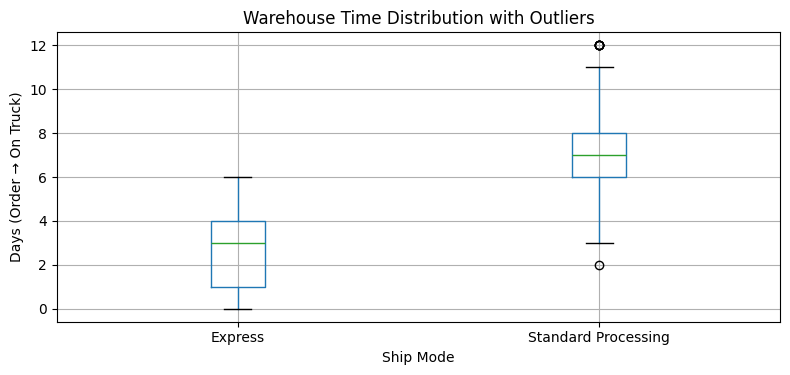

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))

process.boxplot(column='total_warehouse_days', by='Ship Mode', ax=ax)

ax.set_title('Warehouse Time Distribution with Outliers')
ax.set_xlabel('Ship Mode')
ax.set_ylabel('Days (Order → On Truck)')
plt.suptitle('')  # removes the automatic pandas title that looks ugly
plt.tight_layout()
plt.show()

- Why did some standard orders get processed so fast? Were they simple orders? Were they placed on a specific day? 
- It's the kind of question that could lead to useful business insights — 
- if we understand why those were fast, maybe you can replicate it for all orders! :D 
- But I did not analyse that 

### 5.2 Does Day of Order Affect Warehouse Time?
Weekend orders should take longer since the warehouse only operates Mon–Fri.

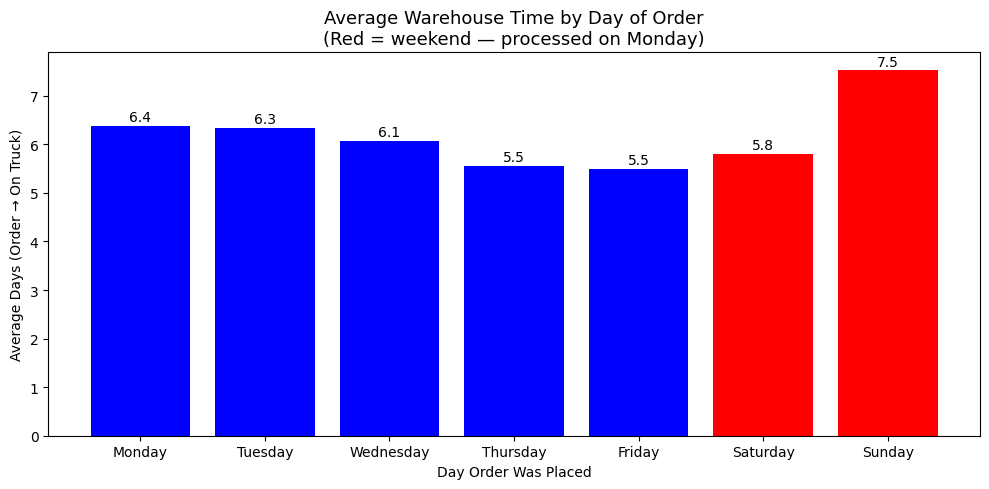

In [ ]:
avg_by_day = process.groupby('order_day')['total_warehouse_days'].mean().reindex(day_order)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['red' if d in ['Saturday', 'Sunday'] else 'blue' for d in day_order]
ax.bar(avg_by_day.index, avg_by_day.values, color=colors)
ax.set_title('Average Warehouse Time by Day of Order\n(Red = weekend — processed on Monday)', fontsize=13)
ax.set_ylabel('Average Days (Order → On Truck)')
ax.set_xlabel('Day Order Was Placed')
#i wanted to add the values on top of the bars and I asked google for some fance help :3
for i, (day, val) in enumerate(avg_by_day.items()):
    ax.text(i, val + 0.1, f'{val:.1f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

### 5.3 Express vs Standard — Is Express Worth It?

/var/folders/9r/34wtgz5j61jckm4p_gfmq0vw0000gn/T/ipykernel_14657/2720684526.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([standard, express], labels=['Standard Processing', 'Express'], patch_artist=True,


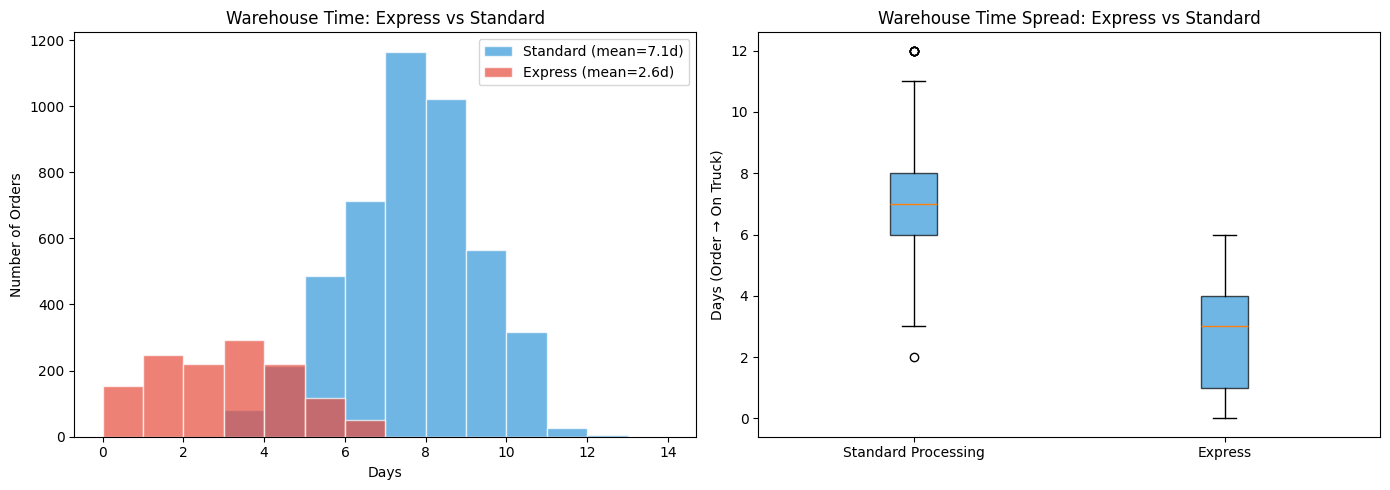

Express saves on average 4.6 days in warehouse time


In [36]:
express = process[process['Ship Mode'] == 'Express']['total_warehouse_days']
standard = process[process['Ship Mode'] == 'Standard Processing']['total_warehouse_days']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram comparison
axes[0].hist(standard, bins=range(0, 15), alpha=0.7, color='#3498db', label=f'Standard (mean={standard.mean():.1f}d)', edgecolor='white')
axes[0].hist(express, bins=range(0, 15), alpha=0.7, color='#e74c3c', label=f'Express (mean={express.mean():.1f}d)', edgecolor='white')
axes[0].set_title('Warehouse Time: Express vs Standard', fontsize=12)
axes[0].set_xlabel('Days')
axes[0].set_ylabel('Number of Orders')
axes[0].legend()

# Boxplot comparison
axes[1].boxplot([standard, express], labels=['Standard Processing', 'Express'], patch_artist=True,
                boxprops=dict(facecolor='#3498db', alpha=0.7))
axes[1].set_title('Warehouse Time Spread: Express vs Standard', fontsize=12)
axes[1].set_ylabel('Days (Order → On Truck)')

plt.tight_layout()
plt.show()

print(f'Express saves on average {standard.mean() - express.mean():.1f} days in warehouse time')

### 5.4 Delivery Reliability — How Consistent is the Logistics Company?

In [37]:
print('Delivery Time Breakdown:')
delivery_counts = has_delivery['delivery_days'].value_counts().sort_index()
delivery_pct = has_delivery['delivery_days'].value_counts(normalize=True).sort_index() * 100

summary_delivery = pd.DataFrame({'Count': delivery_counts, 'Percentage': delivery_pct.round(1)})
display(summary_delivery)

on_time = (has_delivery['delivery_days'] <= 3).sum()
print(f'\nOrders delivered in 3 days or less: {on_time} ({on_time/len(has_delivery):.1%})')
print(f'Orders taking MORE than 3 days: {len(has_delivery) - on_time} ({(len(has_delivery)-on_time)/len(has_delivery):.1%})')

Delivery Time Breakdown:


,Count,Percentage
delivery_days,,
1.0,4,0.6
2.0,40,6.0
3.0,97,14.5
4.0,89,13.3
5.0,350,52.4
6.0,50,7.5
7.0,38,5.7



Orders delivered in 3 days or less: 141 (21.1%)
Orders taking MORE than 3 days: 527 (78.9%)


## 6. Key Findings Summary

In [38]:
print('=' * 60)
print('KEY FINDINGS SUMMARY')
print('=' * 60)

print(f"""
📦 WAREHOUSE PROCESSING (Order → Ready to Ship)
   Company claims: ~2 days
   Actual average: {has_intern['processing_time'].mean():.1f} days
   → ❌ Takes MORE than twice as long as claimed!

🚛 WAITING FOR TRUCK (Ready to Ship → On Truck)
   Company claims: ships on next truck (Mon/Wed/Fri)
   Actual average: {has_intern['wait_for_truck'].mean():.1f} days wait
   → ⚠️ Mostly aligns, but some orders wait up to 3 days

📬 DELIVERY (On Truck → Customer)
   Logistics claims: ~3 days average
   Actual average: {has_delivery['delivery_days'].mean():.1f} days
   → ❌ Consistently longer than promised!

⚡ EXPRESS vs STANDARD
   Standard avg total warehouse time: {standard.mean():.1f} days
   Express avg total warehouse time:  {express.mean():.1f} days
   → ✅ Express clearly faster, saves ~{standard.mean()-express.mean():.1f} days

📅 WEEKEND ORDERS
   Weekend orders represent {len(weekend_orders)/len(process):.1%} of all orders
   → These orders take longer as expected (processed on Monday)
""")

KEY FINDINGS SUMMARY

📦 WAREHOUSE PROCESSING (Order → Ready to Ship)
   Company claims: ~2 days
   Actual average: 4.3 days
   → ❌ Takes MORE than twice as long as claimed!

🚛 WAITING FOR TRUCK (Ready to Ship → On Truck)
   Company claims: ships on next truck (Mon/Wed/Fri)
   Actual average: 1.8 days wait
   → ⚠️ Mostly aligns, but some orders wait up to 3 days

📬 DELIVERY (On Truck → Customer)
   Logistics claims: ~3 days average
   Actual average: 4.6 days
   → ❌ Consistently longer than promised!

⚡ EXPRESS vs STANDARD
   Standard avg total warehouse time: 7.1 days
   Express avg total warehouse time:  2.6 days
   → ✅ Express clearly faster, saves ~4.6 days

📅 WEEKEND ORDERS
   Weekend orders represent 15.6% of all orders
   → These orders take longer as expected (processed on Monday)



## 7. Final Overview Dashboard

/var/folders/9r/34wtgz5j61jckm4p_gfmq0vw0000gn/T/ipykernel_14657/2834418636.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot([standard, express], labels=['Standard', 'Express'], patch_artist=True,


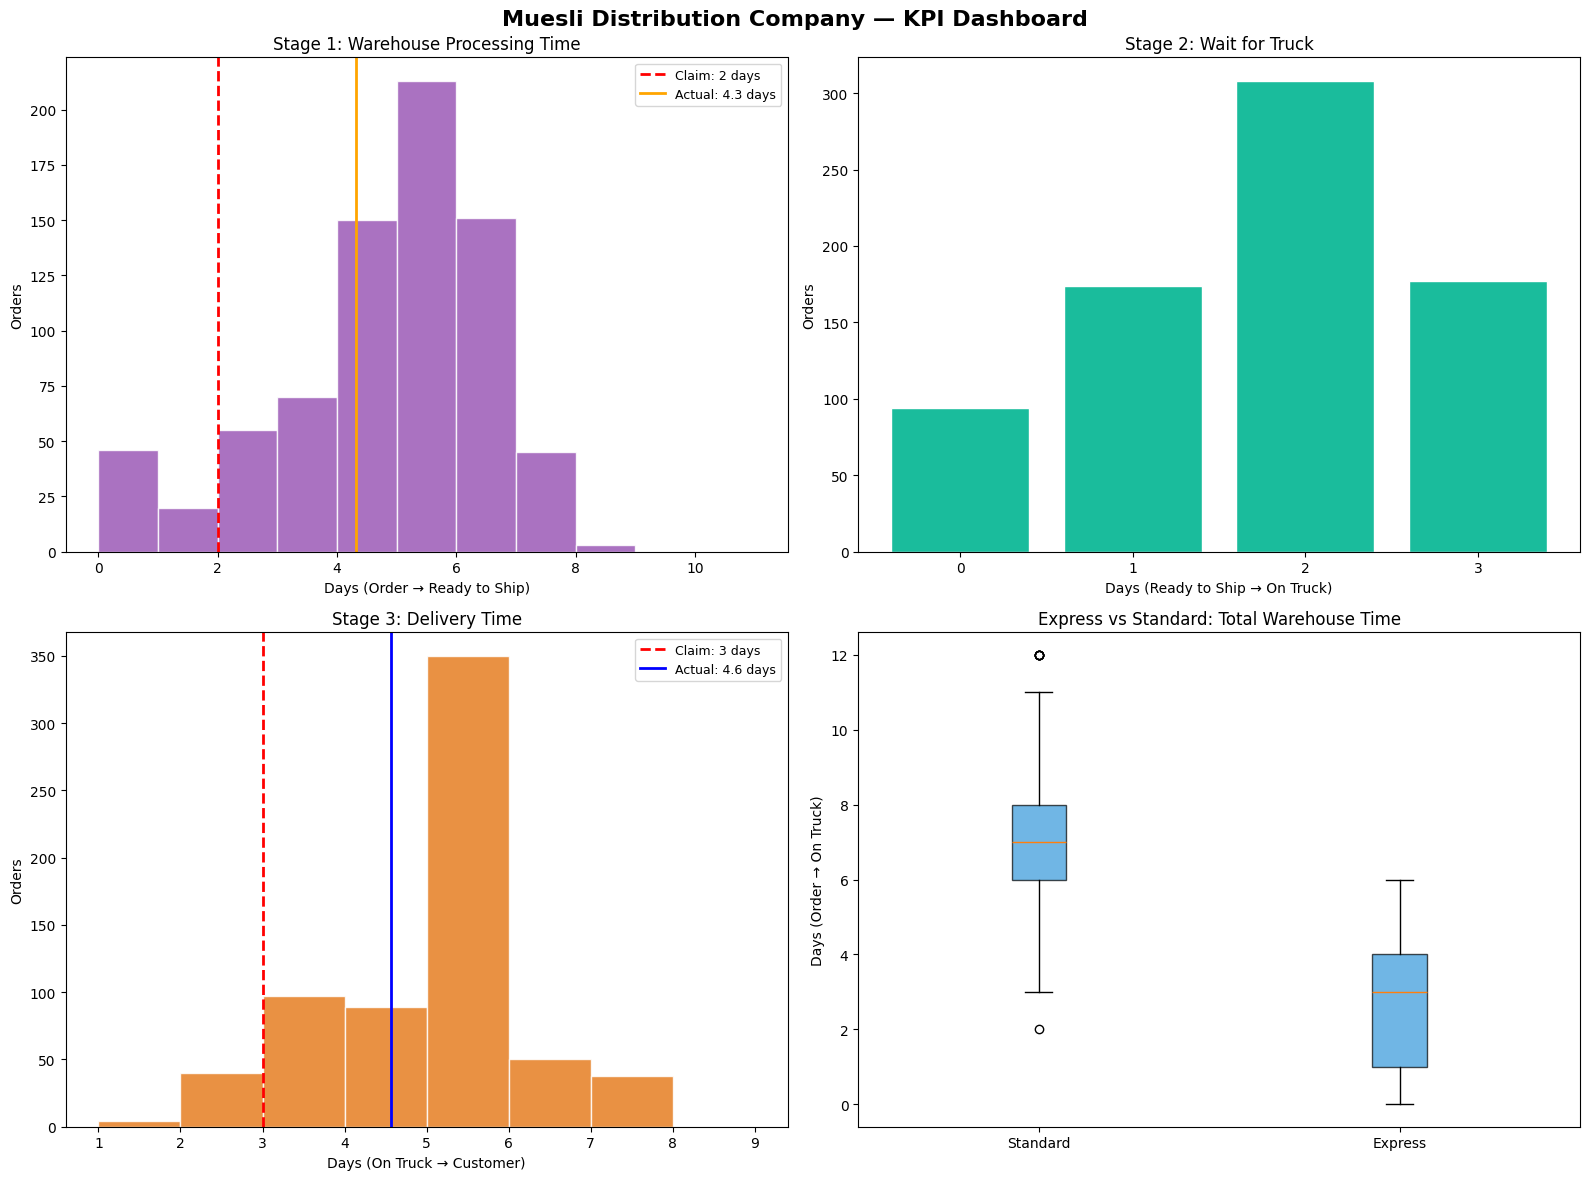

Dashboard saved as kpi_dashboard.png


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Muesli Distribution Company — KPI Dashboard', fontsize=16, fontweight='bold')

# Plot 1: Processing time (intern data)
axes[0, 0].hist(has_intern['processing_time'], bins=range(0, 12), color='#9b59b6', edgecolor='white', alpha=0.85)
axes[0, 0].axvline(x=2, color='red', linestyle='--', linewidth=2, label='Claim: 2 days')
axes[0, 0].axvline(x=has_intern['processing_time'].mean(), color='orange', linewidth=2,
                   label=f'Actual: {has_intern["processing_time"].mean():.1f} days')
axes[0, 0].set_title('Stage 1: Warehouse Processing Time')
axes[0, 0].set_xlabel('Days (Order → Ready to Ship)')
axes[0, 0].set_ylabel('Orders')
axes[0, 0].legend(fontsize=9)

# Plot 2: Wait for truck
wait_counts = has_intern['wait_for_truck'].value_counts().sort_index()
axes[0, 1].bar(wait_counts.index, wait_counts.values, color='#1abc9c', edgecolor='white')
axes[0, 1].set_title('Stage 2: Wait for Truck')
axes[0, 1].set_xlabel('Days (Ready to Ship → On Truck)')
axes[0, 1].set_ylabel('Orders')
axes[0, 1].set_xticks([0, 1, 2, 3])

# Plot 3: Delivery time
axes[1, 0].hist(has_delivery['delivery_days'], bins=range(1, 10), color='#e67e22', edgecolor='white', alpha=0.85)
axes[1, 0].axvline(x=3, color='red', linestyle='--', linewidth=2, label='Claim: 3 days')
axes[1, 0].axvline(x=has_delivery['delivery_days'].mean(), color='blue', linewidth=2,
                   label=f'Actual: {has_delivery["delivery_days"].mean():.1f} days')
axes[1, 0].set_title('Stage 3: Delivery Time')
axes[1, 0].set_xlabel('Days (On Truck → Customer)')
axes[1, 0].set_ylabel('Orders')
axes[1, 0].legend(fontsize=9)

# Plot 4: Express vs Standard
axes[1, 1].boxplot([standard, express], labels=['Standard', 'Express'], patch_artist=True,
                   boxprops=dict(facecolor='#3498db', alpha=0.7))
axes[1, 1].set_title('Express vs Standard: Total Warehouse Time')
axes[1, 1].set_ylabel('Days (Order → On Truck)')

plt.tight_layout()
plt.savefig('kpi_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved as kpi_dashboard.png')

## 8. Conclusions & Recommendations

### What the data tells us:

1. **The warehouse is the biggest bottleneck** — processing takes ~4.3 days on average, more than double the claimed 2 days. This is the most concerning finding.

2. **The logistics company is also underperforming** — delivery takes ~4.6 days on average, not 3. Only ~21% of orders arrive within the promised 3 days.

3. **Express processing is effective** — it reduces total warehouse time from ~7 days to ~2.6 days. Worth investigating if it could be offered more broadly.

4. **Weekend orders add delay** — ~15% of orders are placed on weekends and naturally take longer since the warehouse is closed.

### Caveats:
- **Intern data is partial** (only 290 of ~5900 orders) — conclusions about warehouse processing should be treated carefully
- **Campaign data is partial** (only 333 orders) — only customers who scanned the QR code are included, which may not be representative

### Recommended KPIs to track going forward:
| KPI | Target |
|---|---|
| Average warehouse processing time | ≤ 2 days |
| % orders processed within 2 days | ≥ 80% |
| Average delivery time | ≤ 3 days |
| % orders delivered within 3 days | ≥ 80% |
| Express vs Standard time saving | Monitor monthly |